# Ghost region pruning: translucent Gaussians that differ from ground truth

Open this notebook in VS Code and connect it to a **Google Colab GPU runtime**. Run the cells from top to bottom. Colab clones or fast-forwards the repository, so **commit and push the code you want to test to the repository's default branch first**.

The experiment targets translucent ghost copies: faint, slightly shifted duplicates that are most visible where the reference image is black. It works on regions rather than single Gaussians:

1. **Eligibility safeguard:** only Gaussians with opacity ≤ `TRANSLUCENT_MAX_OPACITY` (0.4) can be removed.
2. **Flagged pixels:** pixels where the render differs from the reference by at least `DIFF_THRESHOLD` in any RGB channel.
3. **Evidence:** translucent Gaussians whose centers project into flagged pixels on the selection views.
4. **Clusters:** evidence-seeded clusters of translucent Gaussians that are close in position, color, and opacity.
5. **Ablation:** each cluster is removed alone and kept only if flagged pixels drop on the selection views without an MAE regression.
6. **Held-out check:** accepted clusters are removed together and compared with an opacity-matched baseline on views never used for selection.

Results are written to `/content/ghost_region_pruning/` inside the Colab runtime, so no Google Drive mount is needed. The last cell packs them into `/content/ghost_region_pruning.zip` and provides two ways to copy that archive to your computer. Flagged pixels are marked in red, and accepted cluster centers in cyan.


In [2]:
import os
import pathlib
import subprocess

repo_url = 'https://github.com/jon-of-us/gaussian-splatting-homwork.git'
assignment_root = pathlib.Path('/content/hw1_2026_student')

if (assignment_root / '.git').is_dir():
    subprocess.run(
        ['git', '-C', str(assignment_root), 'pull', '--ff-only'],
        check=True,
    )
elif assignment_root.exists():
    raise FileExistsError(
        f'{assignment_root} exists but is not a Git checkout. '
        'Rename it in the Colab runtime, then rerun this cell.'
    )
else:
    subprocess.run(
        ['git', 'clone', '--depth', '1', repo_url, str(assignment_root)],
        check=True,
    )

required_files = [
    assignment_root / 'gaussian_model.py',
    assignment_root / 'submodules/diff-gaussian-rasterization/cuda_rasterizer/forward.cu',
    assignment_root / 'scripts/setup_environment.sh',
    assignment_root / 'scripts/ghost_region_pruning.py',
    assignment_root / 'assets/gs_cloud.ply',
]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f'Repository checkout is missing required files: {missing_files}')

os.chdir(assignment_root)
print(f'Assignment directory: {pathlib.Path.cwd()}')

Assignment directory: /content/hw1_2026_student


In [3]:
import pathlib
import subprocess
import sys
import torch
import torchvision
import torch.utils.cpp_extension

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Connect to a Colab GPU runtime, then rerun.')
if torch.utils.cpp_extension.CUDA_HOME is None:
    raise RuntimeError('CUDA Toolkit was not found. Use a Colab GPU runtime with nvcc installed.')

subprocess.run(['nvidia-smi'], check=True)
nvcc = pathlib.Path(torch.utils.cpp_extension.CUDA_HOME) / 'bin' / 'nvcc'
if not nvcc.is_file():
    raise FileNotFoundError(f'CUDA compiler was not found: {nvcc}')
subprocess.run([str(nvcc), '--version'], check=True)

print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'torchvision: {torchvision.__version__}')
print(f'PyTorch CUDA: {torch.version.cuda}')
print(f'GPU: {torch.cuda.get_device_name(0)}')

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4


## Build the CUDA extension

This uses the repository setup helper and the notebook kernel's Python. Run it once per fresh Colab runtime.

In [4]:
import os
import sys
import subprocess

build_env = os.environ.copy()
build_env['HW1_PYTHON'] = sys.executable
build_env['MAX_JOBS'] = '2'
subprocess.run(
    ['bash', 'scripts/setup_environment.sh'],
    cwd=assignment_root,
    env=build_env,
    check=True,
)

CompletedProcess(args=['bash', 'scripts/setup_environment.sh'], returncode=0)

## Configuration

Selection views drive candidate generation and acceptance. Held-out views are used only for the final comparison. `TRANSLUCENT_MAX_OPACITY` is the safeguard: Gaussians above it are never removed by this method.

Results stay in the runtime at `output_dir`. The last cell archives them and, when `UPLOAD_RESULTS_TO_GITHUB` is enabled and a `GITHUB_TOKEN` is available, also commits the archive to `RESULTS_BRANCH` so you can fetch it with `git`.


In [5]:
import pathlib
import sys

for import_path in (assignment_root, assignment_root / 'scripts'):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))

SH_DEGREE = 1
SELECTION_VIEWS = (0, 1, 2)
HELD_OUT_VIEWS = (3, 4)
TRANSLUCENT_MAX_OPACITY = 0.4
DIFF_THRESHOLD = 0.05  # largest RGB channel difference that counts as a flagged pixel (about 13/255)
EVIDENCE_DILATION_PX = 4
NEIGHBOR_RADIUS_MULTIPLIER = 4.0
COLOR_TOLERANCE = 0.05  # largest per-channel RGB gap between linked Gaussians
OPACITY_TOLERANCE = 0.1  # largest opacity gap between linked Gaussians
MIN_VIEWS_WITH_EVIDENCE = 2
MAX_CLUSTER_MEMBERS = 5000
TOP_K_CLUSTERS = 20
MAX_MAE_REGRESSION = 0.001
UPLOAD_RESULTS_TO_GITHUB = True
RESULTS_BRANCH = 'ghost-region-pruning-results'

output_dir = pathlib.Path('/content/ghost_region_pruning')
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Selection views: {SELECTION_VIEWS}; held-out views: {HELD_OUT_VIEWS}')
print(f'Output directory: {output_dir}')


Selection views: (0, 1, 2); held-out views: (3, 4)
Output directory: /content/ghost_region_pruning


## Load the model, cameras, references, and baseline renders

The baseline is the unmodified model rendered with the same black background as `render.py`.

In [6]:
import PIL.Image
import numpy
import torch
import render
import gaussian_model
import ghost_region_pruning as ghost_pruning

camera_files = sorted((assignment_root / 'assets/cameras').glob('*.npy'))
cameras = []
for camera_file in camera_files:
    config = numpy.load(camera_file, allow_pickle=True).item()
    cameras.append(render.Camera(
        config['R'], config['T'], config['FoVx'], config['FoVy'],
        config['image_width'], config['image_height'],
    ))
ALL_VIEWS = tuple(range(len(cameras)))

model = gaussian_model.GaussianModel(SH_DEGREE)
model.load_ply(str(assignment_root / 'assets/gs_cloud.ply'))
gaussian_count = model.get_xyz.shape[0]
background = torch.tensor([0.0, 0.0, 0.0], dtype=torch.float32, device='cuda')

references = []
for view in ALL_VIEWS:
    reference_np = numpy.asarray(PIL.Image.open(assignment_root / f'assets/gt/{view}.png').convert('RGB'))
    reference = torch.tensor(reference_np, dtype=torch.float32, device='cuda') / 255.0
    if reference.shape[:2] != (cameras[view].image_height, cameras[view].image_width):
        raise ValueError(f'Reference {view} shape {tuple(reference.shape)} does not match its camera')
    references.append(reference)


def render_view(camera, gaussians):
    with torch.no_grad():
        image = render.render(camera, gaussians, background)['render']
    return image.permute(1, 2, 0).clamp(0.0, 1.0)


def metrics_for(image, view):
    return ghost_pruning.image_metrics(image, references[view], DIFF_THRESHOLD)


baseline_images = {view: render_view(cameras[view], model) for view in ALL_VIEWS}
baseline_metrics = {view: metrics_for(baseline_images[view], view) for view in ALL_VIEWS}
print(f'Gaussians: {gaussian_count}')
for view in ALL_VIEWS:
    print('View {}: MAE {:.5f}, flagged pixels {}'.format(view, baseline_metrics[view]['mae'], baseline_metrics[view]['flagged_pixels']))

Gaussians: 257882
View 0: MAE 0.01537, flagged pixels 85938
View 1: MAE 0.01857, flagged pixels 115277
View 2: MAE 0.02067, flagged pixels 106332
View 3: MAE 0.02005, flagged pixels 149159
View 4: MAE 0.01789, flagged pixels 140547


## Flagged pixels and translucent evidence

A pixel is flagged when the baseline render differs from the reference by at least `DIFF_THRESHOLD` in any RGB channel, on any background. Evidence is a Gaussian center that projects into a flagged pixel, after dilating the flagged mask by `EVIDENCE_DILATION_PX`. Only translucent Gaussians can become candidates.

In [7]:
centers = model.get_xyz.detach()
opacity = model.get_opacity.detach().reshape(-1)
translucent = ghost_pruning.translucent_mask(opacity, TRANSLUCENT_MAX_OPACITY)
print(f'Translucent candidates (opacity <= {TRANSLUCENT_MAX_OPACITY}): {int(translucent.sum())} of {gaussian_count}')

flagged_raw = {}
evidence_rows = []
for view in SELECTION_VIEWS:
    flagged_raw[view] = ghost_pruning.flagged_pixel_mask(
        baseline_images[view], references[view], DIFF_THRESHOLD
    )
    dilated = ghost_pruning.dilate_mask(flagged_raw[view], EVIDENCE_DILATION_PX)
    pixels, inside = ghost_pruning.project_centers(cameras[view], centers)
    evidence = ghost_pruning.evidence_mask(pixels, inside, dilated)
    evidence_rows.append(evidence)
    print('View {}: flagged pixels {}, translucent evidence Gaussians {}'.format(
        view, int(flagged_raw[view].sum()), int((evidence & translucent).sum())))

evidence_np = torch.stack(evidence_rows).cpu().numpy()

Translucent candidates (opacity <= 0.4): 151885 of 257882
View 0: flagged pixels 85938, translucent evidence Gaussians 115789
View 1: flagged pixels 115277, translucent evidence Gaussians 113606
View 2: flagged pixels 106332, translucent evidence Gaussians 103124


## Group evidence into clusters

Two translucent Gaussians are linked when their centers lie within `NEIGHBOR_RADIUS_MULTIPLIER` times the median of each Gaussian's largest scale, every RGB channel differs by at most `COLOR_TOLERANCE`, and their opacities differ by at most `OPACITY_TOLERANCE`. A cluster is a connected group of linked Gaussians that contains at least one Gaussian with translucent evidence.

In [8]:
median_max_scale = float(model.get_scaling.detach().max(dim=1).values.median())
neighbor_radius = NEIGHBOR_RADIUS_MULTIPLIER * median_max_scale
rgb_np = ghost_pruning.base_colors(model).cpu().numpy()
clusters, cluster_stats = ghost_pruning.build_feature_clusters(
    centers.cpu().numpy(), rgb_np, opacity.cpu().numpy(), translucent.cpu().numpy(), evidence_np,
    neighbor_radius, COLOR_TOLERANCE, OPACITY_TOLERANCE,
)
selected = ghost_pruning.select_clusters(clusters, MIN_VIEWS_WITH_EVIDENCE, MAX_CLUSTER_MEMBERS, TOP_K_CLUSTERS)
print('Median largest scale: {:.5f}; neighbor radius: {:.5f}'.format(median_max_scale, neighbor_radius))
print('Translucent candidates: {}'.format(cluster_stats['candidates']))
print('Linked pairs: {} within radius -> {} within color (<= {}) -> {} within opacity (<= {})'.format(
    cluster_stats['pairs_within_radius'], cluster_stats['pairs_within_color'], COLOR_TOLERANCE,
    cluster_stats['pairs_within_opacity'], OPACITY_TOLERANCE))
print('Connected components: {}; with translucent evidence: {}'.format(
    cluster_stats['components'], cluster_stats['components_with_evidence']))
sizes = sorted(cluster['member_count'] for cluster in clusters)
if sizes:
    print('Cluster sizes: min {}, median {}, max {}; larger than MAX_CLUSTER_MEMBERS: {}'.format(
        sizes[0], sizes[len(sizes) // 2], sizes[-1], sum(size > MAX_CLUSTER_MEMBERS for size in sizes)))
print('Clusters: {}; selected for ablation: {}'.format(len(clusters), len(selected)))
for cluster in selected:
    print('cluster {}: members {}, evidence Gaussians {}, views {}, hits {}, opacity mean {:.3f} (spread {:.3f}), max RGB spread {:.3f}'.format(
        cluster['id'], cluster['member_count'], cluster['evidence_gaussians'],
        cluster['views_with_evidence'], cluster['evidence_hits'],
        cluster['opacity_mean'], cluster['opacity_spread'], float(cluster['rgb_spread'].max())))

Median largest scale: 0.01594; neighbor radius: 0.06376
Translucent candidates: 151885
Linked pairs: 25050442 within radius -> 2352955 within color (<= 0.05) -> 1564663 within opacity (<= 0.1)
Connected components: 30729; with translucent evidence: 27374
Cluster sizes: min 1, median 1, max 16504; larger than MAX_CLUSTER_MEMBERS: 6
Clusters: 27374; selected for ablation: 20
cluster 50: members 4347, evidence Gaussians 4335, views 3, hits 9982, opacity mean 0.154 (spread 0.397), max RGB spread 0.954
cluster 160: members 2905, evidence Gaussians 2900, views 3, hits 8250, opacity mean 0.121 (spread 0.398), max RGB spread 0.867
cluster 257: members 3464, evidence Gaussians 3308, views 3, hits 7952, opacity mean 0.114 (spread 0.397), max RGB spread 0.776
cluster 158: members 4252, evidence Gaussians 4230, views 3, hits 7902, opacity mean 0.064 (spread 0.396), max RGB spread 0.416
cluster 6: members 3438, evidence Gaussians 3142, views 3, hits 7282, opacity mean 0.116 (spread 0.398), max RGB 

## Ablate each cluster on the selection views

Each cluster is removed alone and re-rendered on the selection views. It is accepted only if the total flagged pixels drop and no selection view's MAE rises by more than `MAX_MAE_REGRESSION`.

In [9]:
selection_before = [baseline_metrics[view] for view in SELECTION_VIEWS]
accepted = []
ablation_rows = []
for cluster in selected:
    removed = torch.as_tensor(cluster['member_indices'], dtype=torch.long, device=centers.device)
    trial = ghost_pruning.subset_model(
        model, ghost_pruning.keep_mask_without(gaussian_count, removed, centers.device)
    )
    selection_after = [metrics_for(render_view(cameras[view], trial), view) for view in SELECTION_VIEWS]
    flagged_delta = sum(after['flagged_pixels'] for after in selection_after) - sum(before['flagged_pixels'] for before in selection_before)
    mae_delta = max(after['mae'] - before['mae'] for before, after in zip(selection_before, selection_after))
    is_accepted = ghost_pruning.cluster_is_accepted(selection_before, selection_after, MAX_MAE_REGRESSION)
    if is_accepted:
        accepted.append(cluster)
        reason = 'accepted'
    elif flagged_delta >= 0:
        reason = 'flagged did not drop'
    else:
        reason = 'MAE regression above tolerance'
    ablation_rows.append({
        'cluster_id': cluster['id'],
        'members': cluster['member_count'],
        'evidence_views': cluster['views_with_evidence'],
        'evidence_hits': cluster['evidence_hits'],
        'opacity_mean': round(cluster['opacity_mean'], 4),
        'opacity_spread': round(cluster['opacity_spread'], 4),
        'rgb_spread_max': round(float(cluster['rgb_spread'].max()), 4),
        'flagged_delta': flagged_delta,
        'max_mae_delta': mae_delta,
        'accepted': is_accepted,
        'reason': reason,
    })
    per_view = ', '.join(
        'view {}: {} -> {}'.format(view, before['flagged_pixels'], after['flagged_pixels'])
        for view, before, after in zip(SELECTION_VIEWS, selection_before, selection_after)
    )
    print('cluster {}: members {}, flagged [{}], flagged delta {:+d}, max MAE delta {:+.5f}, accepted {} ({})'.format(
        cluster['id'], cluster['member_count'], per_view, flagged_delta, mae_delta, is_accepted, reason))
    del trial
    torch.cuda.empty_cache()
print('Accepted clusters: {} of {}'.format(len(accepted), len(selected)))

cluster 50: members 4347, flagged [view 0: 85938 -> 86605, view 1: 115277 -> 115277, view 2: 106332 -> 108627], flagged delta +2962, max MAE delta +0.00005, accepted False (flagged did not drop)
cluster 160: members 2905, flagged [view 0: 85938 -> 86626, view 1: 115277 -> 116665, view 2: 106332 -> 106562], flagged delta +2306, max MAE delta +0.00004, accepted False (flagged did not drop)
cluster 257: members 3464, flagged [view 0: 85938 -> 86493, view 1: 115277 -> 115515, view 2: 106332 -> 106588], flagged delta +1049, max MAE delta +0.00003, accepted False (flagged did not drop)
cluster 158: members 4252, flagged [view 0: 85938 -> 92164, view 1: 115277 -> 118146, view 2: 106332 -> 106332], flagged delta +9095, max MAE delta +0.00017, accepted False (flagged did not drop)
cluster 6: members 3438, flagged [view 0: 85938 -> 87292, view 1: 115277 -> 118467, view 2: 106332 -> 110077], flagged delta +8289, max MAE delta +0.00005, accepted False (flagged did not drop)
cluster 506: members 23

## Remove accepted clusters and compare on held-out views

Accepted clusters are removed together. The opacity-matched baseline removes the same number of Gaussians with the lowest opacity from all Gaussians. It controls for how many Gaussians are removed, not for where they are.

In [10]:
if accepted:
    removed_all = torch.as_tensor(
        numpy.concatenate([cluster['member_indices'] for cluster in accepted]),
        dtype=torch.long, device=centers.device,
    )
else:
    removed_all = torch.zeros(0, dtype=torch.long, device=centers.device)
removed_count = int(removed_all.numel())
print('Removed Gaussians: {} ({:.3%} of all Gaussians)'.format(removed_count, removed_count / gaussian_count))

cluster_pruned = ghost_pruning.subset_model(
    model, ghost_pruning.keep_mask_without(gaussian_count, removed_all, centers.device)
)
opacity_matched = ghost_pruning.subset_model(
    model,
    ghost_pruning.keep_mask_without(
        gaussian_count,
        ghost_pruning.lowest_opacity_indices(opacity, removed_count),
        centers.device,
    ),
)
pruned_models = {'cluster_pruned': cluster_pruned, 'opacity_matched': opacity_matched}
images = {'baseline': baseline_images}
for name, gaussians in pruned_models.items():
    images[name] = {view: render_view(cameras[view], gaussians) for view in ALL_VIEWS}
metrics = {name: {view: metrics_for(images[name][view], view) for view in ALL_VIEWS} for name in images}

print('{:<16}{:<11}{:>5}{:>10}{:>10}{:>10}'.format('variant', 'split', 'view', 'MAE', 'PSNR', 'flagged'))
for name in images:
    for view in ALL_VIEWS:
        split = 'selection' if view in SELECTION_VIEWS else 'held-out'
        row = metrics[name][view]
        print('{:<16}{:<11}{:>5}{:>10.5f}{:>10.2f}{:>10}'.format(
            name, split, view, row['mae'], row['psnr_db'], row['flagged_pixels']))

held_out_summary = {}
for name in images:
    held = [metrics[name][view] for view in HELD_OUT_VIEWS]
    held_out_summary[name] = {
        'mae': sum(row['mae'] for row in held) / len(held),
        'psnr_db': sum(row['psnr_db'] for row in held) / len(held),
        'flagged_pixels': sum(row['flagged_pixels'] for row in held) / len(held),
    }
    print('held-out mean, {}: MAE {:.5f}, flagged {:.0f}'.format(
        name, held_out_summary[name]['mae'], held_out_summary[name]['flagged_pixels']))

Removed Gaussians: 0 (0.000% of all Gaussians)
variant         split       view       MAE      PSNR   flagged
baseline        selection      0   0.01537     32.90     85938
baseline        selection      1   0.01857     31.11    115277
baseline        selection      2   0.02067     31.45    106332
baseline        held-out       3   0.02005     30.79    149159
baseline        held-out       4   0.01789     31.57    140547
cluster_pruned  selection      0   0.01537     32.90     85938
cluster_pruned  selection      1   0.01857     31.11    115277
cluster_pruned  selection      2   0.02067     31.45    106332
cluster_pruned  held-out       3   0.02005     30.79    149159
cluster_pruned  held-out       4   0.01789     31.57    140547
opacity_matched selection      0   0.01537     32.90     85938
opacity_matched selection      1   0.01857     31.11    115277
opacity_matched selection      2   0.02067     31.45    106332
opacity_matched held-out       3   0.02005     30.79    149159
opacity_

## Save marked outputs

For every view, the `*_flagged.png` files mark that variant's flagged pixels in red. The baseline files also mark accepted cluster centers in cyan. `view_N_comparison.png` shows the four panels side by side. Metrics go to `metrics_by_view.csv`, `cluster_ablation.csv`, and `summary.json`.

Read the held-out rows first. The result supports the idea only if `cluster_pruned` lowers held-out flagged pixels relative to `opacity_matched` without a clear MAE regression.


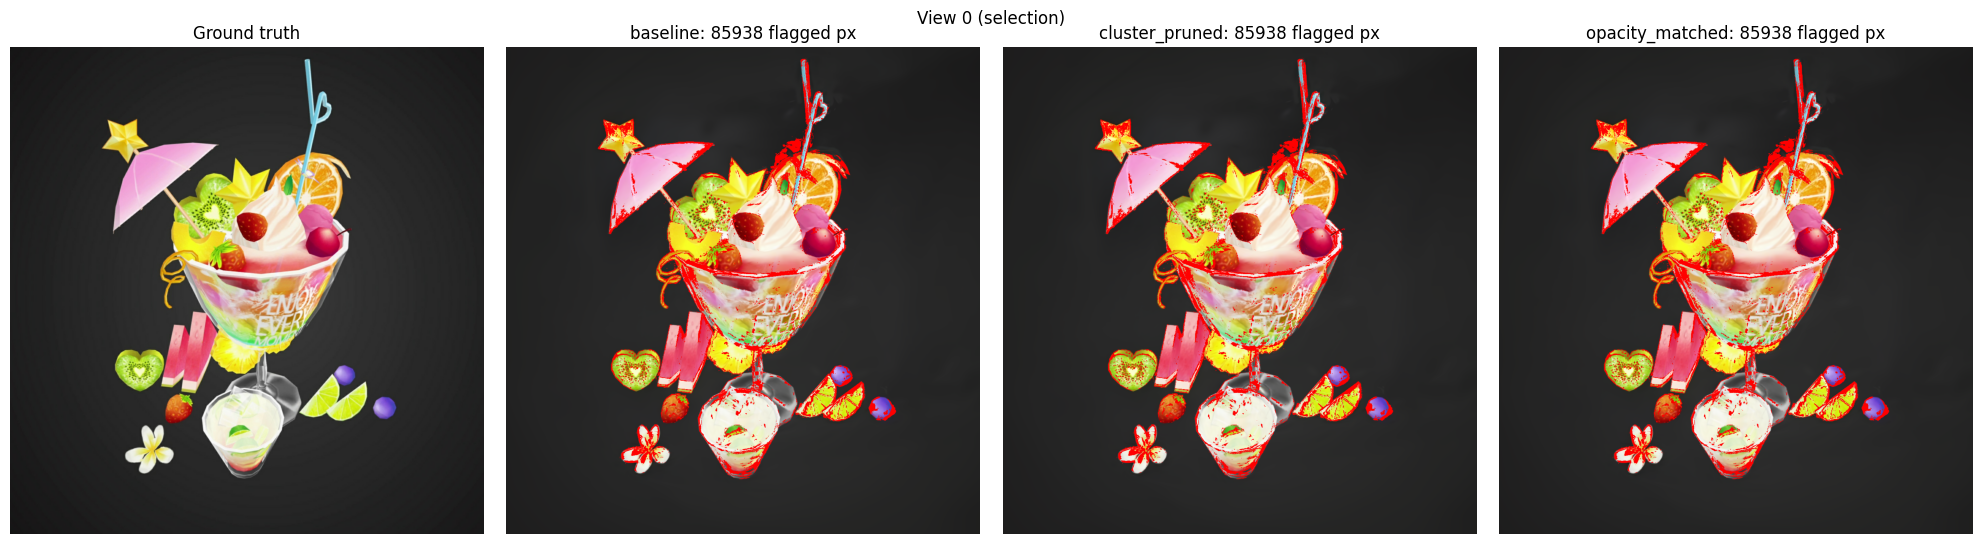

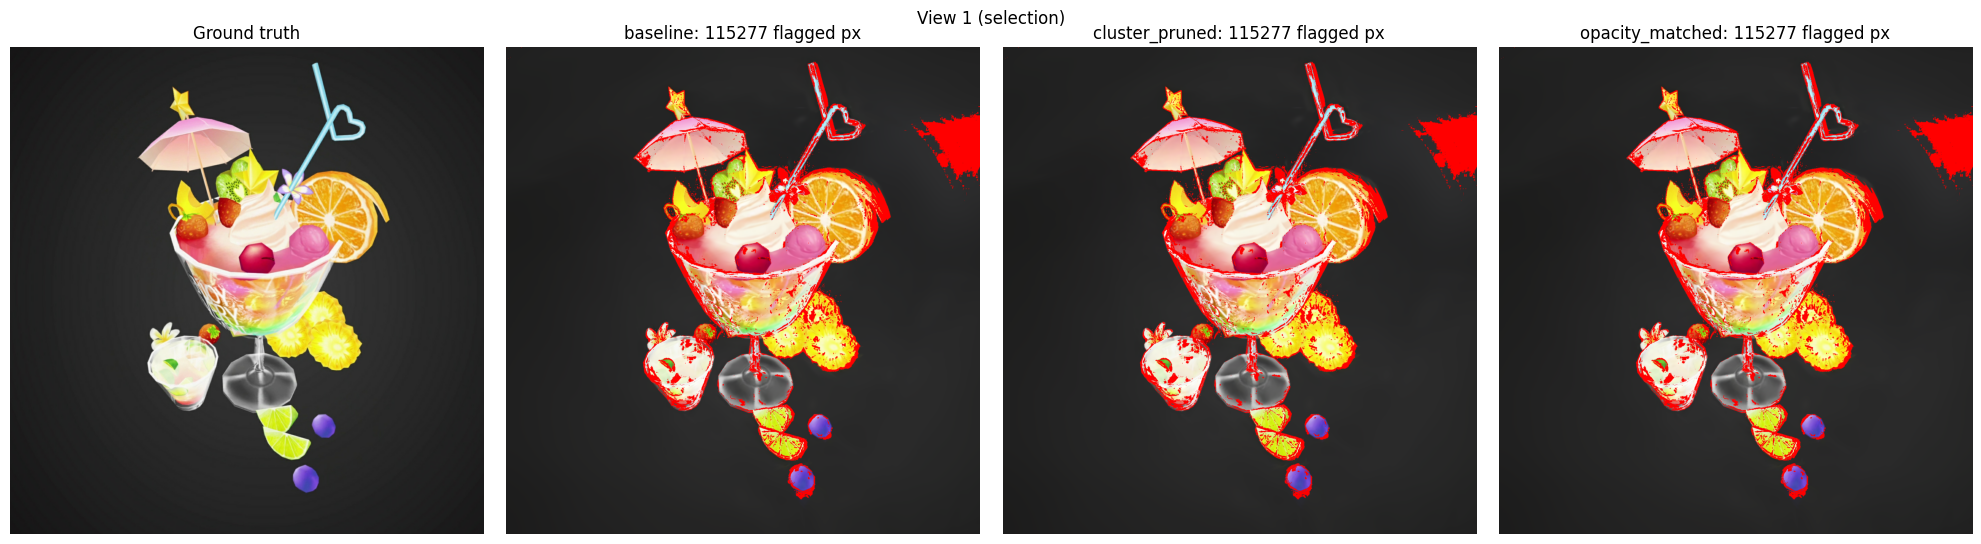

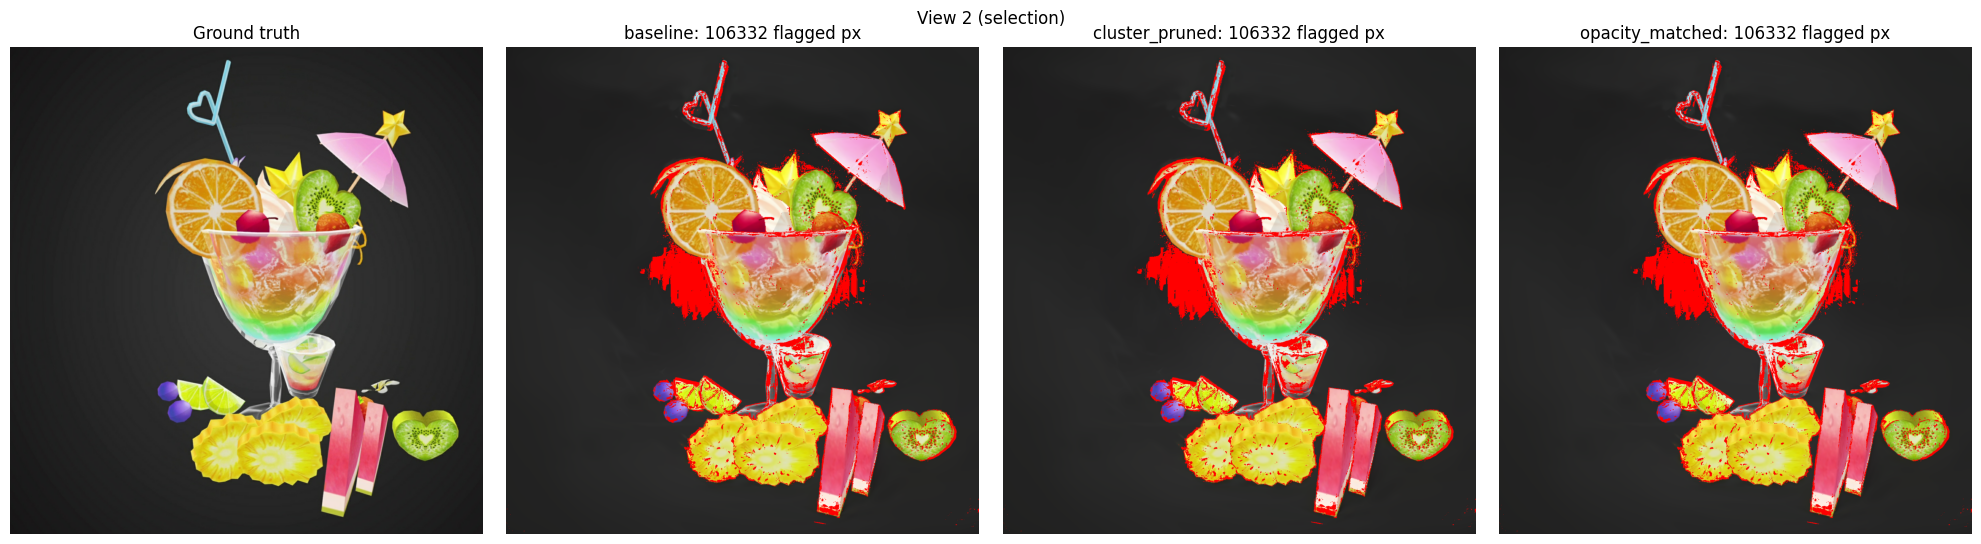

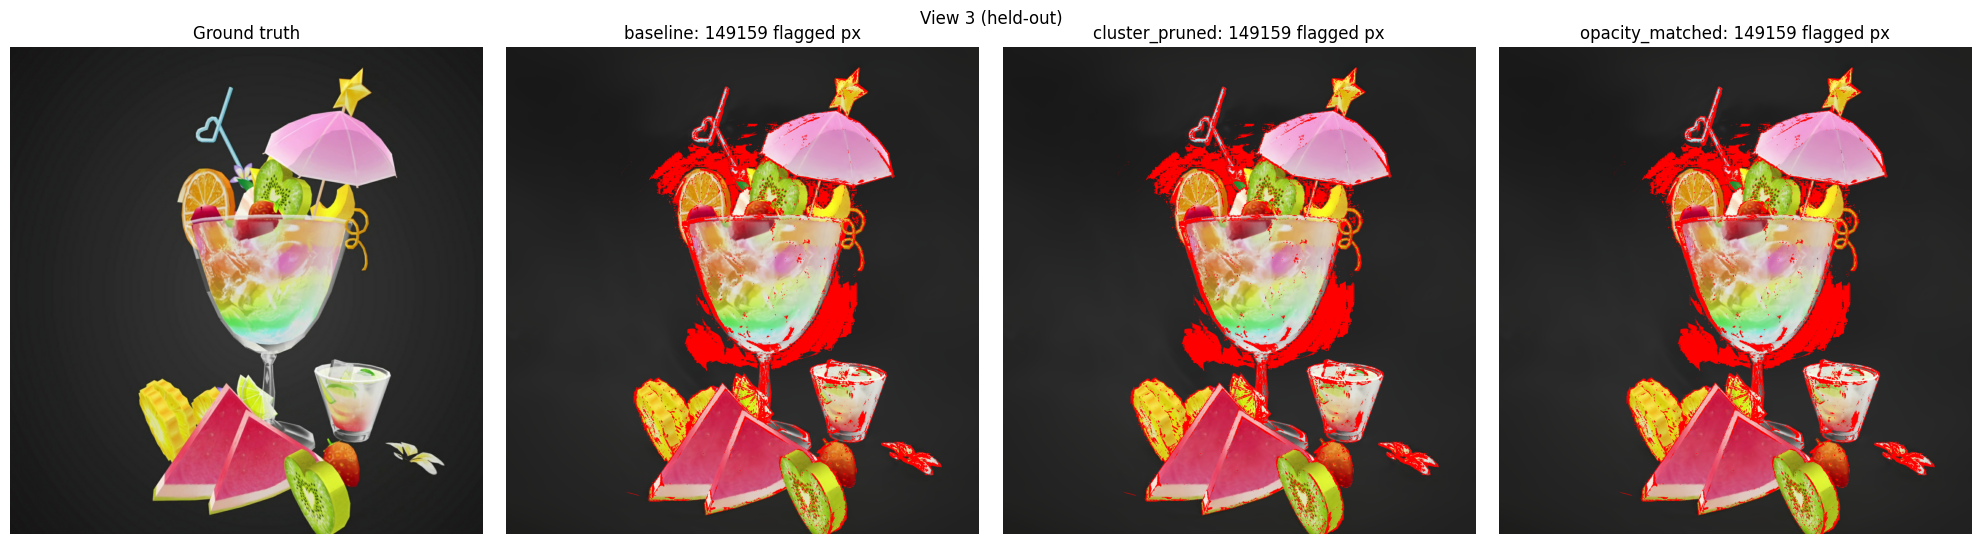

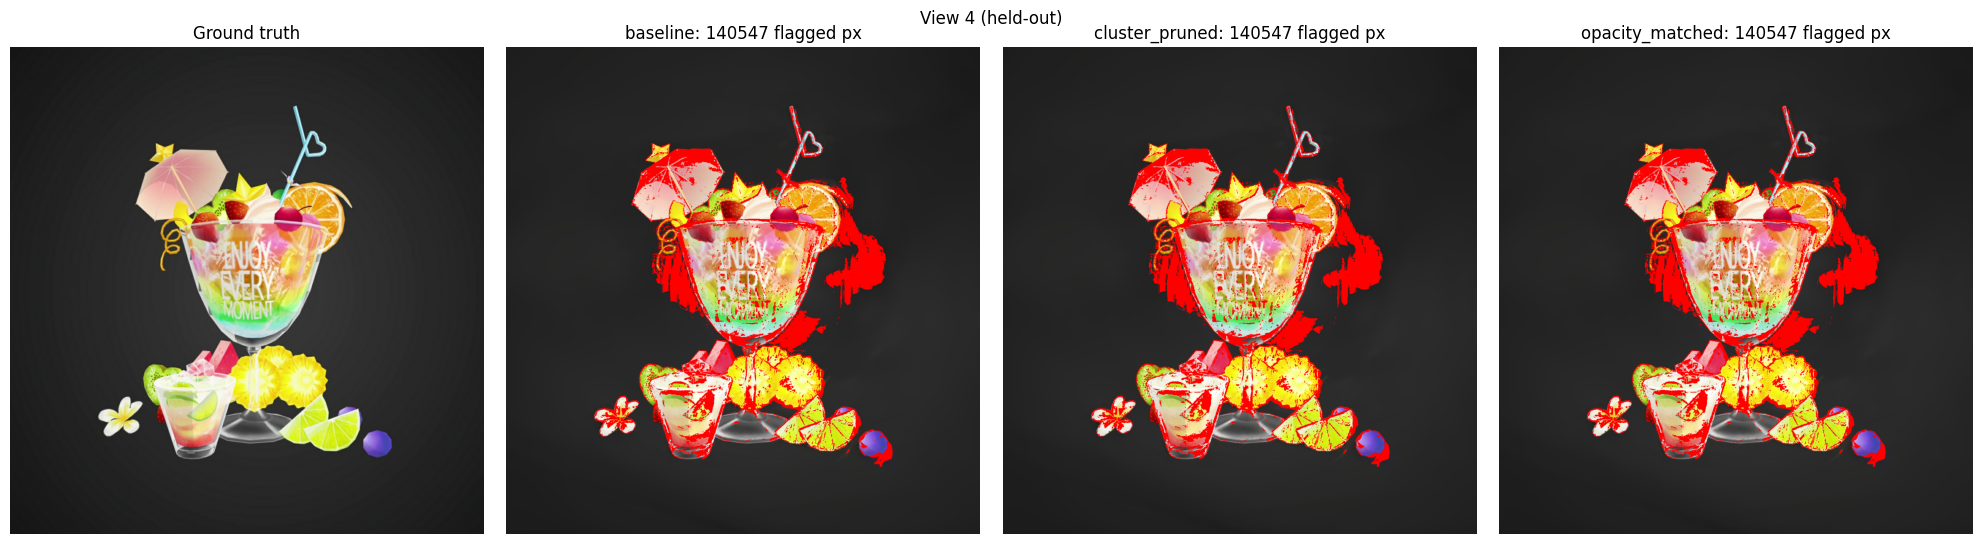

Saved outputs to /content/ghost_region_pruning


In [11]:
import csv
import json
import matplotlib.pyplot as plt


def to_uint8(image):
    return (image.clamp(0.0, 1.0) * 255.0).round().to(torch.uint8).cpu().numpy()


def overlay_centers(image_uint8, pixels_xy, color=(0, 255, 255), half_size=2):
    height, width = image_uint8.shape[:2]
    rows = numpy.clip(numpy.round(pixels_xy[:, 1]).astype(numpy.int64), 0, height - 1)
    columns = numpy.clip(numpy.round(pixels_xy[:, 0]).astype(numpy.int64), 0, width - 1)
    for offset_y in range(-half_size, half_size + 1):
        for offset_x in range(-half_size, half_size + 1):
            image_uint8[
                numpy.clip(rows + offset_y, 0, height - 1),
                numpy.clip(columns + offset_x, 0, width - 1),
            ] = color
    return image_uint8


accepted_mask = torch.zeros(gaussian_count, dtype=torch.bool, device=centers.device)
accepted_mask[removed_all] = True
for view in ALL_VIEWS:
    split = 'selection' if view in SELECTION_VIEWS else 'held-out'
    pixels, inside = ghost_pruning.project_centers(cameras[view], centers)
    accepted_pixels = pixels[inside & accepted_mask].cpu().numpy()
    flagged = {}
    marked = {}
    for name in images:
        flagged[name] = ghost_pruning.flagged_pixel_mask(images[name][view], references[view], DIFF_THRESHOLD)
        marked[name] = ghost_pruning.mark_pixels(images[name][view], flagged[name])
    marked['baseline'] = overlay_centers(marked['baseline'], accepted_pixels)
    for name in images:
        PIL.Image.fromarray(marked[name]).save(output_dir / f'view_{view}_{name}_flagged.png')

    figure, axes = plt.subplots(1, 4, figsize=(20, 5.5))
    axes[0].imshow(to_uint8(references[view]))
    axes[0].set_title('Ground truth')
    for axis, name in zip(axes[1:], images):
        axis.imshow(marked[name])
        axis.set_title(f'{name}: {int(flagged[name].sum())} flagged px')
    for axis in axes:
        axis.axis('off')
    figure.suptitle(f'View {view} ({split})')
    figure.tight_layout()
    figure.savefig(output_dir / f'view_{view}_comparison.png', dpi=120)
    plt.show()
    plt.close(figure)

with (output_dir / 'metrics_by_view.csv').open('w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow(['variant', 'split', 'view', 'mae', 'psnr_db', 'flagged_pixels'])
    for name in images:
        for view in ALL_VIEWS:
            row = metrics[name][view]
            split = 'selection' if view in SELECTION_VIEWS else 'held_out'
            writer.writerow([name, split, view, row['mae'], row['psnr_db'], row['flagged_pixels']])

with (output_dir / 'cluster_ablation.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=['cluster_id', 'members', 'evidence_views', 'evidence_hits', 'opacity_mean', 'opacity_spread', 'rgb_spread_max', 'flagged_delta', 'max_mae_delta', 'accepted', 'reason'])
    writer.writeheader()
    writer.writerows(ablation_rows)

summary = {
    'config': {
        'sh_degree': SH_DEGREE,
        'selection_views': list(SELECTION_VIEWS),
        'held_out_views': list(HELD_OUT_VIEWS),
        'translucent_max_opacity': TRANSLUCENT_MAX_OPACITY,
        'diff_threshold': DIFF_THRESHOLD,
        'evidence_dilation_px': EVIDENCE_DILATION_PX,
        'neighbor_radius_multiplier': NEIGHBOR_RADIUS_MULTIPLIER,
        'neighbor_radius': neighbor_radius,
        'color_tolerance': COLOR_TOLERANCE,
        'opacity_tolerance': OPACITY_TOLERANCE,
        'min_views_with_evidence': MIN_VIEWS_WITH_EVIDENCE,
        'max_cluster_members': MAX_CLUSTER_MEMBERS,
        'top_k_clusters': TOP_K_CLUSTERS,
        'max_mae_regression': MAX_MAE_REGRESSION,
    },
    'gaussian_count': gaussian_count,
    'removed_count': removed_count,
    'clustering': cluster_stats,
    'accepted_clusters': [
        {
            'id': cluster['id'],
            'members': cluster['member_count'],
            'bbox_min': cluster['bbox_min'].tolist(),
            'bbox_max': cluster['bbox_max'].tolist(),
            'rgb_mean': [round(float(value), 4) for value in cluster['rgb_mean']],
            'opacity_mean': round(cluster['opacity_mean'], 4),
        }
        for cluster in accepted
    ],
    'held_out_mean': held_out_summary,
}
with (output_dir / 'summary.json').open('w') as handle:
    json.dump(summary, handle, indent=2)
print('Saved outputs to {}'.format(output_dir))

## Collect the results on your computer

Colab runtime storage disappears when the runtime is recycled, so copy the archive out before you disconnect. This cell zips `output_dir`, asks the Colab frontend for a browser download, and optionally commits the archive to a results branch in the repository.

Two routes work without Google Drive:

1. **Browser download:** run this cell while the notebook is open in browser Colab. The frontend prompts for `ghost_region_pruning.zip`; save it, then unzip it locally.
2. **Git branch:** store a `GITHUB_TOKEN` with repository write access as a Colab secret or an environment variable. The archive is committed to `RESULTS_BRANCH`, so `git fetch origin ghost-region-pruning-results` brings it to your computer from any editor, including VS Code.


In [12]:
import base64
import json
import os
import pathlib
import shutil
import urllib.error
import urllib.request

archive_path = pathlib.Path(
    shutil.make_archive(str(output_dir.parent / output_dir.name), 'zip', root_dir=output_dir)
)
archive_size_mb = archive_path.stat().st_size / 1e6
print('Results archive: {} ({:.2f} MB)'.format(archive_path, archive_size_mb))

try:
    import google.colab.files as colab_files
    colab_files.download(str(archive_path))
    print('Requested a browser download. Save the archive before disconnecting the runtime.')
except Exception as error:
    print('No browser download prompt in this frontend ({}).'.format(error))


def github_token():
    token = os.environ.get('GITHUB_TOKEN', '').strip()
    if token:
        return token
    try:
        import google.colab.userdata as colab_userdata
    except ImportError:
        return ''
    try:
        return colab_userdata.get('GITHUB_TOKEN').strip()
    except Exception:
        return ''


def github_request(url, token, method='GET', payload=None):
    data = None if payload is None else json.dumps(payload).encode('utf-8')
    request = urllib.request.Request(url, data=data, method=method, headers={
        'Authorization': 'Bearer ' + token,
        'Accept': 'application/vnd.github+json',
        'X-GitHub-Api-Version': '2022-11-28',
        'User-Agent': 'ghost-region-pruning-notebook',
    })
    try:
        with urllib.request.urlopen(request) as response:
            return json.loads(response.read() or b'{}')
    except urllib.error.HTTPError as error:
        detail = error.read().decode('utf-8', 'replace')[:300]
        raise RuntimeError('GitHub API {} {} returned {}: {}'.format(method, url, error.code, detail)) from error


def upload_archive(archive, token, branch):
    repo_slug = repo_url.removesuffix('.git').split('github.com/', 1)[-1]
    api = 'https://api.github.com/repos/' + repo_slug
    try:
        github_request('{}/git/ref/heads/{}'.format(api, branch), token)
    except RuntimeError:
        default_branch = github_request(api, token)['default_branch']
        head_sha = github_request(
            '{}/git/ref/heads/{}'.format(api, default_branch), token
        )['object']['sha']
        github_request('{}/git/refs'.format(api), token, 'POST', {
            'ref': 'refs/heads/' + branch,
            'sha': head_sha,
        })
    endpoint = '{}/contents/results/{}'.format(api, archive.name)
    payload = {
        'message': 'Add ghost region pruning results',
        'content': base64.b64encode(archive.read_bytes()).decode('ascii'),
        'branch': branch,
    }
    try:
        payload['sha'] = github_request('{}?ref={}'.format(endpoint, branch), token)['sha']
    except RuntimeError:
        pass
    return github_request(endpoint, token, 'PUT', payload)['commit']['html_url']


token = github_token() if UPLOAD_RESULTS_TO_GITHUB else ''
if not UPLOAD_RESULTS_TO_GITHUB:
    print('UPLOAD_RESULTS_TO_GITHUB is disabled, so the archive was not uploaded.')
elif archive_size_mb > 90.0:
    print('Archive is larger than the 90 MB GitHub file limit, so it was not uploaded.')
elif not token:
    print('No GITHUB_TOKEN found. Export GITHUB_TOKEN, or add a Colab secret with that name,')
    print('then rerun this cell to commit the archive to branch {}.'.format(RESULTS_BRANCH))
else:
    try:
        commit_url = upload_archive(archive_path, token, RESULTS_BRANCH)
        print('Committed the archive to {}: {}'.format(RESULTS_BRANCH, commit_url))
        print('On your computer:')
        print('  git fetch origin {}'.format(RESULTS_BRANCH))
        print('  git checkout origin {} -- results/{}'.format(RESULTS_BRANCH, archive_path.name))
    except (RuntimeError, KeyError, OSError) as error:
        print('GitHub upload failed: {}'.format(error))

print('Runtime copy: {}'.format(archive_path))
print('No archive yet? Open the notebook in browser Colab and rerun this cell, or download')
print('{} from the runtime file browser.'.format(archive_path))


Results archive: /content/ghost_region_pruning.zip (15.64 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Requested a browser download. Save the archive before disconnecting the runtime.
No GITHUB_TOKEN found. Export GITHUB_TOKEN, or add a Colab secret with that name,
then rerun this cell to commit the archive to branch ghost-region-pruning-results.
Runtime copy: /content/ghost_region_pruning.zip
No archive yet? Open the notebook in browser Colab and rerun this cell, or download
/content/ghost_region_pruning.zip from the runtime file browser.
